# <a id='toc1_'></a>[MLflow: comparación de experimentos y registro del modelo](#toc0_)

**Table of contents**<a id='toc0_'></a>    
- [MLflow: comparación de experimentos y registro del modelo](#toc1_)    
  - [Experimentos registrados](#toc1_1_)    
  - [Selección del mejor modelo](#toc1_2_)    
  - [Evaluación en test](#toc1_3_)    
  - [Registro en el Model Registry](#toc1_4_)    
  - [Comprobación: cargar el modelo como lo hará la app](#toc1_5_)    
  - [Resumen](#toc1_6_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

> En este notebook usamos MLflow para comparar los seis experimentos de `04_modeling` sin volver a entrenar nada: todo (parámetros, métricas y modelos) lo leemos del registro de MLflow. Elegimos el mejor modelo, lo evaluamos en test y lo registramos en el Model Registry para que la app lo use.

**Objetivos:**
1. Recuperar desde MLflow todos los experimentos y compararlos.
2. Elegir el mejor por F1-macro en validación.
3. Evaluarlo en test.
4. Registrarlo en el Model Registry con el alias `champion`.
5. Comprobar que el modelo registrado se carga y predice igual que lo hará la app.

In [1]:
import json

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
from mlflow import MlflowClient
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

# Estilo de gráficos
plt.style.use('seaborn-v0_8-whitegrid')

from fashion_mlops.config import (
    PROCESSED_DATA_DIR, IMAGES_DIR, RANDOM_STATE, REGISTERED_MODEL_NAME, CHAMPION_ALIAS
)
from fashion_mlops.data.dataset import make_loaders
from fashion_mlops.models.train import get_device, predict, compute_metrics
from fashion_mlops.models.tracking import setup_mlflow
from fashion_mlops.models.predict import load_champion_model, predict_image

In [2]:
experiment = setup_mlflow()
client = MlflowClient()
device = get_device()

print(f"Experimento: {experiment.name} (id {experiment.experiment_id})")

Experimento: masterCategory (id 1)


## <a id='toc1_1_'></a>[Experimentos registrados](#toc0_)

Recuperamos todos los runs terminados del experimento, con sus parámetros y sus mejores métricas en validación:

In [3]:
runs = mlflow.search_runs(
    experiment_names=[experiment.name],
    filter_string="attributes.status = 'FINISHED'",
    order_by=["metrics.best_val_f1_macro DESC"],
)

columns = {
    "tags.mlflow.runName": "run",
    "params.freeze_backbone": "congelada",
    "params.class_weights": "pesos",
    "params.lr": "lr",
    "params.epochs": "epocas",
    "metrics.best_epoch": "mejor_epoca",
    "metrics.best_val_f1_macro": "val_f1_macro",
    "metrics.best_val_balanced_accuracy": "val_balanced_acc",
    "metrics.best_val_accuracy": "val_accuracy",
}

runs_table = runs[[col for col in columns if col in runs.columns]].rename(columns=columns)
runs_table.round(4)

,run,congelada,pesos,lr,epocas,mejor_epoca,val_f1_macro,val_balanced_acc,val_accuracy
0,fine_tuning_30ep,False,False,0.0001,30,28.0,0.8467,0.8389,0.9929
1,fine_tuning_weighted_30ep,False,True,0.0001,30,14.0,0.8292,0.8547,0.9861
2,fine_tuning,False,False,0.0001,5,NaN,0.8124,0.8064,0.9928
3,fine_tuning_weighted,False,True,0.0001,5,NaN,0.7985,0.8628,0.9688
4,feature_extraction_30ep,True,False,0.001,30,25.0,0.7678,0.7689,0.9664
5,feature_extraction,True,False,0.001,3,NaN,0.7597,0.7639,0.9603


Las curvas de F1-macro en validación por época también están guardadas en MLflow:

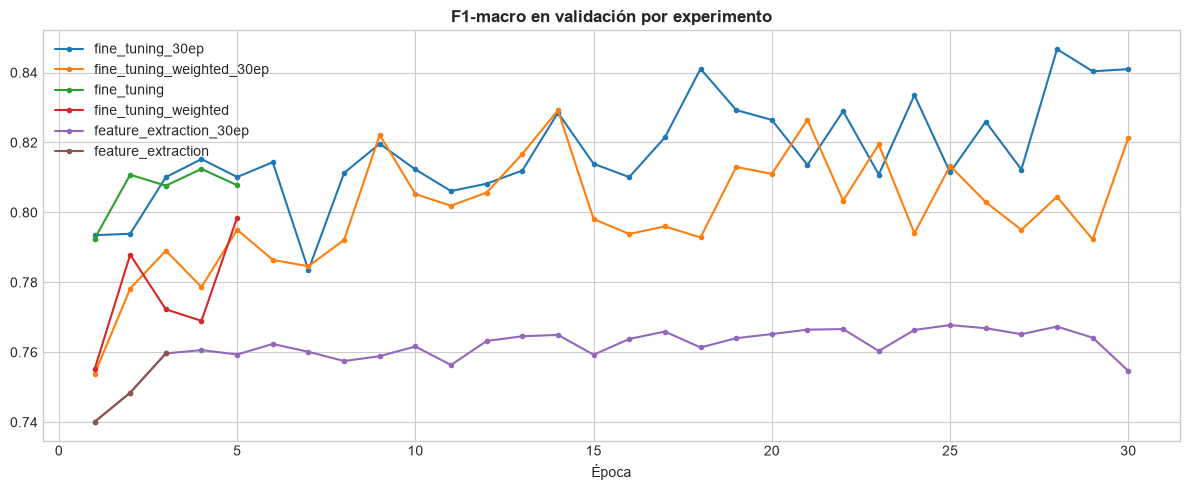

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))

for _, run in runs.iterrows():
    history = sorted(client.get_metric_history(run["run_id"], "val_f1_macro"), key=lambda m: m.step)
    values = [m.value for m in history]

    # Numeramos las épocas desde 1 (en los runs _30ep los steps guardados van de 4 a 33, ver 04_modeling)
    ax.plot(range(1, len(values) + 1), values, marker="o", markersize=3, label=run["tags.mlflow.runName"])

ax.set_xlabel("Época")
ax.set_title("F1-macro en validación por experimento", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

## <a id='toc1_2_'></a>[Selección del mejor modelo](#toc0_)

Elegimos el run con mejor F1-macro en validación. El test no se ha usado para comparar, solo lo usaremos con el modelo elegido.

In [5]:
best_run = runs.iloc[0]
best_run_id = best_run["run_id"]

# En MLflow 3 cada modelo guardado es un "logged model" asociado a su run
best_model_info = mlflow.search_logged_models(
    experiment_ids=[experiment.experiment_id],
    filter_string=f"source_run_id = '{best_run_id}'",
    output_format="list",
)[0]

print(f"Mejor run: {best_run['tags.mlflow.runName']} ({best_run_id})")
print(f"F1-macro en validación: {best_run['metrics.best_val_f1_macro']:.4f}")

Mejor run: fine_tuning_30ep (2ef9ea637d3049e8b297ffc1d829d691)
F1-macro en validación: 0.8467


## <a id='toc1_3_'></a>[Evaluación en test](#toc0_)

In [6]:
df = pd.read_csv(PROCESSED_DATA_DIR / "styles_splits.csv")

with open(PROCESSED_DATA_DIR / "label_mappings.json") as f:
    classes = list(json.load(f)["masterCategory"])

test_loader = make_loaders(df, IMAGES_DIR, label_col="masterCategory_idx")["test"]

best_model = mlflow.pytorch.load_model(f"models:/{best_model_info.model_id}").to(device)

y_true, y_pred, y_prob = predict(best_model, test_loader, device)
test_metrics = compute_metrics(y_true, y_pred)

pd.Series(test_metrics).round(4)

accuracy             0.9926
balanced_accuracy    0.8699
f1_macro             0.8995
dtype: float64

In [7]:
print(classification_report(y_true, y_pred, target_names=classes, digits=3, zero_division=0))

               precision    recall  f1-score   support

  Accessories      0.986     0.992     0.989      1610
      Apparel      0.998     0.994     0.996      3056
     Footwear      0.999     0.998     0.998      1317
        Other      1.000     0.368     0.538        19
Personal Care      0.955     0.997     0.976       343

     accuracy                          0.993      6345
    macro avg      0.988     0.870     0.899      6345
 weighted avg      0.993     0.993     0.992      6345



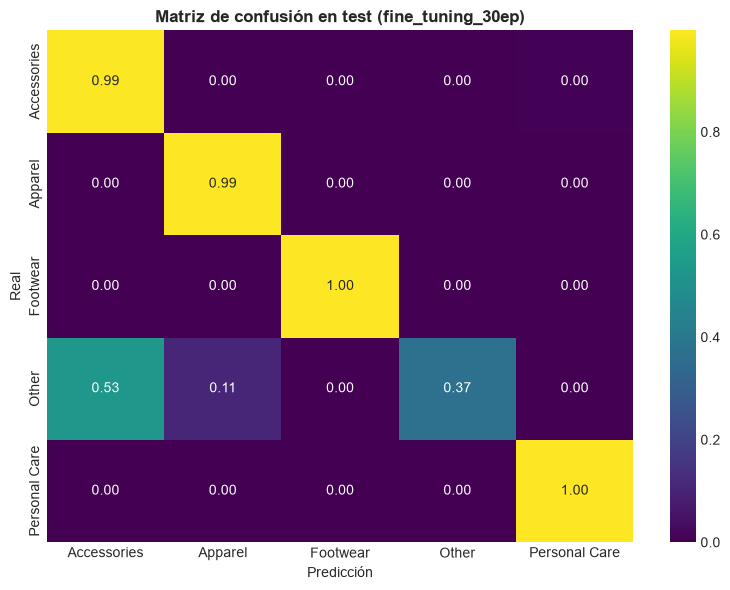

In [8]:
cm = confusion_matrix(y_true, y_pred, normalize="true")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="viridis", xticklabels=classes, yticklabels=classes, ax=ax)
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title(f"Matriz de confusión en test ({best_run['tags.mlflow.runName']})", fontweight="bold")
plt.tight_layout()

# Guardamos las métricas de test y la matriz en el run del modelo elegido
with mlflow.start_run(run_id=best_run_id):
    mlflow.log_metrics({f"test_{k}": v for k, v in test_metrics.items()})
    mlflow.log_figure(fig, "confusion_matrix_test.png")

plt.show()

## <a id='toc1_4_'></a>[Registro en el Model Registry](#toc0_)

Registramos el modelo con el nombre `fashion-mastercategory` y le ponemos el alias `champion`. La app cargará siempre `models:/fashion-mastercategory@champion`, así que si en el futuro entrenamos un modelo mejor, basta con mover el alias sin tocar el código de la app.

In [9]:
model_version = mlflow.register_model(f"models:/{best_model_info.model_id}", REGISTERED_MODEL_NAME)

client.set_registered_model_alias(REGISTERED_MODEL_NAME, CHAMPION_ALIAS, model_version.version)
client.update_model_version(
    REGISTERED_MODEL_NAME,
    model_version.version,
    description=f"ResNet18 ({best_run['tags.mlflow.runName']}) para clasificar masterCategory a partir de la imagen.",
)

for key, value in {"run_name": best_run["tags.mlflow.runName"],
                   "val_f1_macro": round(best_run["metrics.best_val_f1_macro"], 4),
                   "test_f1_macro": round(test_metrics["f1_macro"], 4)}.items():
    client.set_model_version_tag(REGISTERED_MODEL_NAME, model_version.version, key, value)

print(f"Registrado {REGISTERED_MODEL_NAME} versión {model_version.version} con alias '{CHAMPION_ALIAS}'")

Registrado fashion-mastercategory versión 2 con alias 'champion'


Registered model 'fashion-mastercategory' already exists. Creating a new version of this model...
Created version '2' of model 'fashion-mastercategory'.


## <a id='toc1_5_'></a>[Comprobación: cargar el modelo como lo hará la app](#toc0_)

Cargamos el modelo desde el registro (por su alias, sin saber qué run es) y predecimos algunas imágenes de test con `predict_image`, la misma función que usará la app:

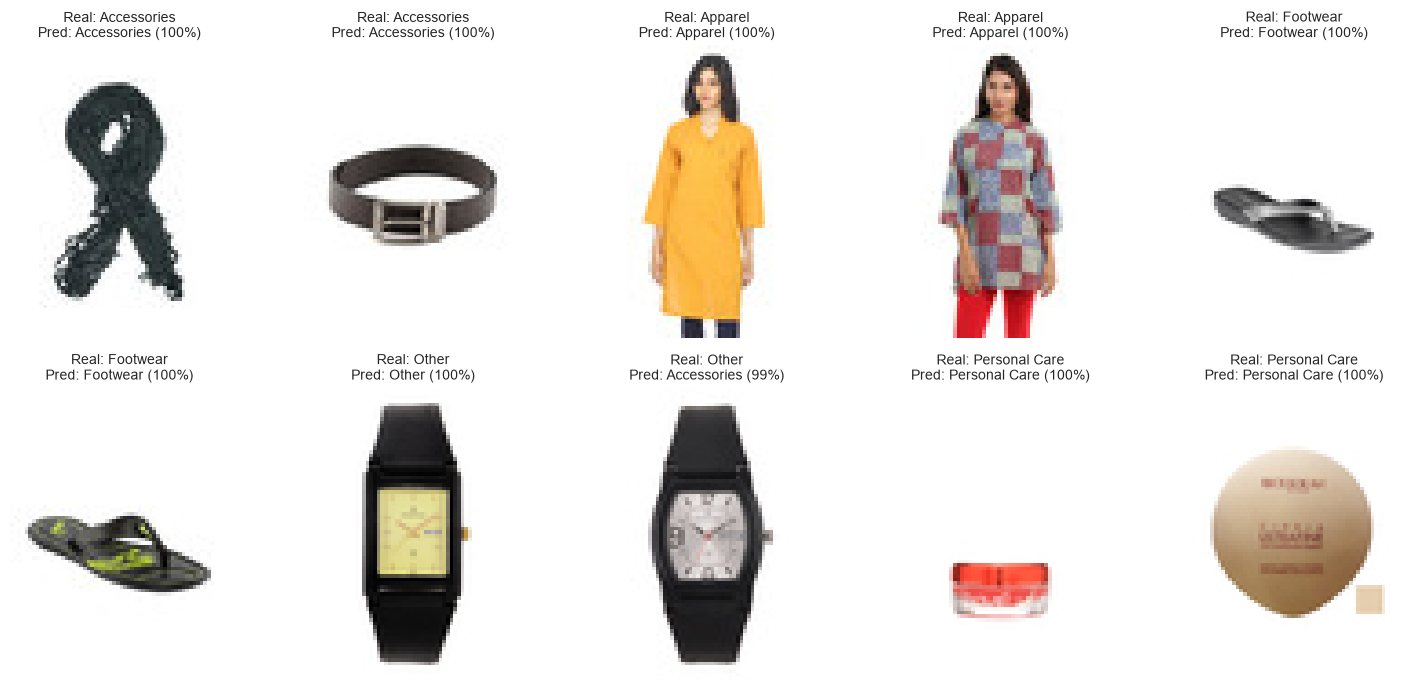

In [10]:
model, model_classes = load_champion_model()

sample = df[df["split"] == "test"].groupby("masterCategory_grouped").sample(2, random_state=RANDOM_STATE)

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for ax, (_, row) in zip(axes.flatten(), sample.iterrows()):
    image = Image.open(IMAGES_DIR / f"{row['id']}.jpg")
    probs = predict_image(model, image, model_classes)
    pred, prob = next(iter(probs.items()))

    ax.imshow(image)
    ax.set_title(f"Real: {row['masterCategory_grouped']}\nPred: {pred} ({prob:.0%})", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

## <a id='toc1_6_'></a>[Resumen](#toc0_)

- Hemos comparado los seis experimentos de `04_modeling` leyendo todo de MLflow (parámetros, métricas por época y modelos), sin volver a entrenar.
- El mejor en validación es el fine-tuning con 30 épocas (`fine_tuning_30ep`, F1-macro 0,847).
- **En test:** accuracy 0,993, balanced accuracy 0,870 y F1-macro 0,899. Mejora claramente a la versión anterior (fine-tuning de 5 épocas, F1-macro 0,846 en test).
- La mejora viene casi toda de `Other`: ahora reconoce 7 de sus 19 imágenes sin ningún falso positivo (F1 0,538 frente a 0,261). Las cuatro categorías visuales siguen por encima de 0,97 de F1.
- Lo hemos registrado como **versión 2** de `fashion-mastercategory` y el alias `champion` ha pasado de la versión 1 a la 2. La app usará el nuevo modelo sin cambiar su código.
- Al cargarlo desde el registro por su alias, predice correctamente las imágenes de prueba, igual que lo hará la app.

En `06_deployment` calcularemos los embeddings del catálogo con este modelo y lanzaremos la app de Streamlit.